In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
from imports import *

# Stanford sessions: timing and design checks, then compile

Stanford tested patients only (P1–P24, each OFF and ON medication). Each session is a folder in `raw/stanford_data/`,
named in one of two styles: `Trem_P10_OFFmeds_gl` / `Brady_P14_ONmeds_rl` (tremor- or bradykinesia-dominant, then
the intended prior) or `P20 OFF`. Inside it:

- trial blocks `YYMMDD_HHMMSS.mat` directly in the session folder;
- practice blocks in `Practice/`, `practice/` or `Practice (failed)/`;
- usually a pre-combined `<name>.mat` and the MATLAB script that made it, `A4_combine_data.m`.

`A4_combine_data.m` concatenates every `.mat` at the top of the folder in name order and saves the result under a name
typed into a dialog, so the combined file's name is not a reliable label. This notebook compiles from the block files
(raw data wherever possible) and uses the combined files only as a cross-check.

The block checks are shared with Harvard (`src/utils/blocks.py`, see notebook 0.02 for the three clocks):

1. **Timing**: filename, MAT header and `time` clock agree, so each block was recorded in its session;
2. **Design**: the per-colour target split and the prior each block implies, consistent across the session;
3. **Order**: practice before trial, blocks in order without overlap, one day, 600+ trials.

Stanford adds: the labels (folder name, combined file name, data), the combined-file cross-check, and an inventory
of `clinical_info/`. It writes `compiled/stanford/{blocks.csv, session_summary.csv, sessions/<session>.parquet}`.
Nothing is screened for accuracy or design here.

In [2]:
import re
from collections import Counter

import scipy.io

from src.data_io import catalog
from src.utils import blocks as blk

STANFORD = catalog.path("raw_stanford_sessions")
STAMP = re.compile(r"^\d{6}_\d{6}$")
SESSION_NAME = re.compile(r"^(?:(?P<subtype>Brady|Trem)_)?P(?P<number>\d+)[ _](?P<med>ON|OFF)(?:meds_(?P<prior>[gr][lr]))?$")
LABEL = re.compile(r"(?:(?P<subtype>Brady|Trem)_)?P(?P<number>\d+)_(?P<med>ON|OFF)meds_(?P<prior>[gr][lr])")


def parse_session(folder):
    found = SESSION_NAME.match(folder.name)
    if not found:
        raise ValueError(f"unrecognised session folder: {folder.name}")
    number, medication = int(found["number"]), found["med"].lower()
    return {"session_id": f"P{number}_{medication}", "subject_id": f"P{number}", "group": "pd", "medication": medication,
            "folder": folder.name, "folder_subtype": found["subtype"], "folder_prior": found["prior"]}


def file_role(file, folder):
    """`trial`, `practice`, `combined` (a pre-combined session file) or `unexpected`, and the subfolder it sits in."""
    parts = file.relative_to(folder).parts
    if len(parts) == 1:
        return ("trial" if STAMP.match(file.stem) else "combined"), ""
    if len(parts) == 2 and parts[0].lower().startswith("practice"):
        return "practice", parts[0]
    return "unexpected", "/".join(parts[:-1])

## 1. Inventory

In [3]:
folders = sorted((f for f in STANFORD.iterdir() if f.is_dir() and f.name != "clinical_info"),
                 key=lambda f: (int(SESSION_NAME.match(f.name)["number"]), f.name.endswith("ON") or "_ON" in f.name))
sessions = pd.DataFrame([parse_session(f) for f in folders])
assert sessions.session_id.is_unique, "two folders for one session"

listing, combined, other_files = [], [], []
for folder, session in zip(folders, sessions.to_dict("records")):
    for file in sorted(folder.rglob("*")):
        if file.is_dir():
            continue
        if file.suffix != ".mat":
            other_files.append({"session_id": session["session_id"], "file": file.relative_to(STANFORD).as_posix()})
            continue
        role, subfolder = file_role(file, folder)
        entry = {**{k: session[k] for k in ("session_id", "subject_id", "group", "medication")},
                 "file": f"{session['session_id']}/{file.relative_to(folder).as_posix()}", "path": file.relative_to(STANFORD).as_posix()}
        if role == "combined":
            combined.append(entry)
        else:
            listing.append({**entry, "phase": role, "subfolder": subfolder})

blocks, decoded = blk.read_blocks(pd.DataFrame(listing), STANFORD)
print(f"{len(folders)} session folders for {sessions.subject_id.nunique()} patients; "
      f"{len(blocks)} block files, {len(combined)} pre-combined files, {len(other_files)} other files")
missing = sorted(set(range(1, sessions.subject_id.str[1:].astype(int).max() + 1)) - set(sessions.subject_id.str[1:].astype(int)))
print("patient numbers with no session folder:", ", ".join(f"P{n}" for n in missing) or "none")
print("practice subfolder names:", dict(Counter(blocks.loc[blocks.phase == "practice", "subfolder"])))
print("other files:", dict(Counter(re.sub(r"^.*/", "", f["file"]) for f in other_files)))
blocks.pivot_table(index="session_id", columns="phase", values="file", aggfunc="size", sort=False).fillna(0).astype(int).T

44 session folders for 22 patients; 250 block files, 33 pre-combined files, 35 other files
patient numbers with no session folder: P5, P21
practice subfolder names: {'practice': 9, 'Practice': 68, 'Practice (failed)': 3}
other files: {'A4_combine_data.m': 34, 'A2_Examples_script.m': 1}


session_id,P1_off,P1_on,P2_off,P2_on,P3_off,P3_on,P4_off,P4_on,P6_off,P6_on,P7_off,P7_on,P8_off,P8_on,P9_off,P9_on,P10_off,P10_on,P11_off,P11_on,P12_off,P12_on,P13_off,P13_on,P14_off,P14_on,P15_off,P15_on,P16_off,P16_on,P17_off,P17_on,P18_off,P18_on,P19_off,P19_on,P20_off,P20_on,P22_off,P22_on,P23_off,P23_on,P24_off,P24_on
phase,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
trial,3,2,4,4,5,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,0,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4
practice,1,0,8,2,2,1,0,2,2,1,4,1,3,1,0,0,2,2,1,2,1,2,4,2,1,1,3,3,2,3,2,1,2,1,1,3,2,2,1,1,1,3,2,1


## 2. Timing checks

In [4]:
blk.check_timing(blocks)
timing_ok = blocks.header_same_day & blocks.saved_after_recording & (blocks.clock_status == "on clock")
print(f"{timing_ok.sum()} of {len(blocks)} files pass all timing checks strictly. The others:")
blocks.loc[~timing_ok, ["file", "filename_time", "header_time", "n_rows", "duration_s", "wait_s", "clock_drift_s", "clock_status"]].round(0)

234 of 250 files pass all timing checks strictly. The others:


,file,filename_time,header_time,n_rows,duration_s,wait_s,clock_drift_s,clock_status
0,P1_off/220805_085832.mat,2022-08-05 08:58:32,2022-08-05 09:06:02,163,431.0,19.0,100.0,clock shift
3,P1_off/practice/220805_085502.mat,2022-08-05 08:55:02,2022-08-05 08:57:06,42,103.0,21.0,101.0,clock shift
10,P2_off/Practice/220902_111623.mat,2022-09-02 11:16:23,2022-09-02 11:22:51,131,313.0,75.0,-2759.0,clock shift
11,P2_off/Practice/220902_112532.mat,2022-09-02 11:25:32,2022-09-02 11:30:28,112,275.0,21.0,-2760.0,clock shift
12,P2_off/Practice/220902_113141.mat,2022-09-02 11:31:41,2022-09-02 11:36:23,108,252.0,30.0,-2760.0,clock shift
13,P2_off/Practice/220902_113815.mat,2022-09-02 11:38:15,2022-09-02 11:43:07,115,274.0,18.0,-2760.0,clock shift
14,P2_off/Practice/220902_114442.mat,2022-09-02 11:44:42,2022-09-02 11:49:19,105,255.0,22.0,-2760.0,clock shift
15,P2_off/Practice/220902_115105.mat,2022-09-02 11:51:05,2022-09-02 11:56:10,106,265.0,40.0,-2760.0,clock shift
77,P8_on/221118_120607.mat,2022-11-18 12:06:07,2022-11-18 12:14:11,163,439.0,45.0,-122.0,clock shift
78,P8_on/221118_121541.mat,2022-11-18 12:15:41,2022-11-18 12:23:20,162,425.0,34.0,-122.0,clock shift


In the data as of 2026-10-20, three kinds of departure appear, none of them a misfiled file:

- **Clock shifts up** (the PC slept in a break, pausing the monotonic clock): every block after the break sits higher
  by the length of the sleep, e.g. P8 ON (+4 min over a 7 min break) and P2 OFF (+46 min over a 72 min gap after
  six practice blocks).
- **Clock shifts down** (the wall clock was corrected, e.g. by a time sync): P1 OFF (−100 s after block 1) and
  P16 OFF (−35 s during block 2, which is why that block's filename is 18 s later than its trials allow).
- **Sessions with no trial blocks**: P15 ON has only `Practice (failed)/`.

Same-day shifts are kept (`clock shift`) and reported per session in `notes`.

In [5]:
blocks.loc[timing_ok, ["wait_s", "clock_drift_s"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
wait_s,234.0,248.5,1074.6,-18.4,17.5,23.3,51.4,13305.6
clock_drift_s,234.0,0.5,4.1,-6.0,-0.2,0.0,0.3,35.7


## 3. Which files are used

In [6]:
blk.mark_use(blocks)
runs = blk.add_provenance(blocks)
print(f"using {blocks.use.sum()} of {len(blocks)} files; left out:")
display(blocks.loc[~blocks.use, ["file", "header_time", "n_rows", "excluded_reason", "duplicate_of"]])
runs

using 246 of 250 files; left out:


,file,header_time,n_rows,excluded_reason,duplicate_of
22,P2_on/Practice/220909_110419.mat,2022-09-09 11:16:38,10,aborted (10 x 9 event matrix),None
155,P15_on/Practice (failed)/230210_102625.mat,2023-02-10 12:11:21,57,session has no trial blocks,None
156,P15_on/Practice (failed)/230210_121321.mat,2023-02-10 12:16:02,52,session has no trial blocks,None
157,P15_on/Practice (failed)/230210_121633.mat,2023-02-10 12:19:07,50,session has no trial blocks,None


,saved_from,saved_to,n_files,recorded_with,filed_under,reasons,copies_of
recording_run,,,,,,,
1.0,2022-09-09 11:16:38,2022-09-09 11:16:38,1,P2_on,P2_on,aborted,
2.0,2023-02-10 12:11:21,2023-02-10 12:19:07,3,no session that day,P15_on,session has no trial blocks,


## 4. Design of each block

As for Harvard: the share of each colour's targets on the right, the implied prior (`gr` green-right, `rl` red-left,
...; `none` if no colour departs from 50:50 by more than 10 points), and the design error.

Practice blocks carry no prior. Unlike Harvard, where practice is 100% coherence only, Stanford practice blocks come
in two kinds: **easy** (100% only, usually 50 or 100 trials) and **full** (all four coherences, often a whole
160-trial block at 50:50).

In [7]:
blk.add_design(blocks, decoded)
practice = blocks[blocks.use & (blocks.phase == "practice")].copy()
practice["kind"] = np.where(practice.coherences == "100", "easy", "full")
print(f"{len(practice)} used practice blocks: {practice.kind.value_counts().to_dict()}; "
      f"with a prior: {(practice.block_prior != 'none').sum()}")
practice_kinds = practice.groupby("session_id", sort=False).apply(
    lambda p: " | ".join(f"{k} {n:.0f}" for k, n in zip(p.sort_values("filename_time").kind, p.sort_values("filename_time").n_shown)), include_groups=False)
display(practice_kinds.rename("practice blocks (kind, trials)").to_frame())

trial_blocks = blocks[blocks.use & (blocks.phase == "trial")]
sizes = trial_blocks.groupby("session_id", sort=False).agg(n_blocks=("file", "size"), shown=("n_shown", lambda n: "+".join(f"{v:.0f}" for v in n)))
print(f"{len(trial_blocks)} used trial blocks, {trial_blocks.partial.sum()} partial. Sessions not run as 4 x 160:")
sizes[(sizes.n_blocks != 4) | ~sizes.shown.eq("160+160+160+160")]

76 used practice blocks: {'easy': 51, 'full': 25}; with a prior: 0


,"practice blocks (kind, trials)"
session_id,
P1_off,easy 42
P2_off,full 100 | full 100 | full 100 | full 100 | fu...
P2_on,full 160
P3_off,full 160 | full 100
P3_on,full 160
P4_on,full 161 | full 50
P6_off,full 160 | full 50
P6_on,full 160
P7_off,full 160 | full 100 | full 100 | full 100


170 used trial blocks, 0 partial. Sessions not run as 4 x 160:


,n_blocks,shown
session_id,,
P1_off,3,160+160+320
P1_on,2,320+320
P2_on,4,161+160+160+160
P3_off,5,160+160+160+160+160
P15_off,4,162+162+160+161
P19_off,4,160+160+161+160
P19_on,4,162+160+160+160


## 5. Session checks

In [8]:
summary = blk.session_summary(blocks)
summary = sessions[["session_id", "folder", "folder_subtype", "folder_prior"]].merge(summary, on="session_id", how="left")
show = ["session_id", "date", "n_practice_blocks", "n_trial_blocks", "n_shown", "block_priors", "session_prior",
        "prior_consistent", "design_ok", "practice_before_trial", "practice_to_trial_min", "block_order_consistent", "issues"]
summary[show].round(1)

,session_id,date,n_practice_blocks,n_trial_blocks,n_shown,block_priors,session_prior,prior_consistent,design_ok,practice_before_trial,practice_to_trial_min,block_order_consistent,issues
0,P1_off,2022-08-05,1,3,640.0,rr | rr | rr,rr,True,True,True,1.4,True,
1,P1_on,2022-08-30,0,2,640.0,gr | gr,gr,True,True,False,NaN,True,no practice recorded in this session
2,P2_off,2022-09-02,8,4,640.0,gl | gl | gl | gl,gl,True,True,True,2.3,True,
3,P2_on,2022-09-09,1,4,641.0,rl | rl | rl | rl,rl,True,True,True,1.8,True,1 file(s) left out
4,P3_off,2022-09-30,2,5,800.0,rr | rr | rr | rr | rr,rr,True,True,True,2.4,True,
5,P3_on,2022-10-07,1,4,640.0,gl | gr | gr | gr,gr,False,True,True,2.3,True,block priors differ (gl | gr | gr | gr)
6,P4_off,2022-10-28,0,4,640.0,rl | rl | rl | rl,rl,True,True,False,NaN,True,no practice recorded in this session
7,P4_on,2022-09-30,2,4,640.0,gl | gl | gl | gl,gl,True,True,True,1.4,True,
8,P6_off,2022-11-11,2,4,640.0,rl | rl | rl | rl,rl,True,True,True,1.4,True,
9,P6_on,2022-11-18,1,4,640.0,gl | gl | gl | gl,gl,True,True,True,9.2,True,


## 6. Labels and the pre-combined files

Three places name a session's prior: the folder (`..._gl`), the pre-combined file's name, and the data
(`session_prior`, from the blocks). Each pre-combined file is also compared with its session's trial blocks
concatenated in name order, which is what `A4_combine_data.m` does.

In [9]:
combined = pd.DataFrame(combined)


def matches_blocks(row):
    parts = blocks[(blocks.session_id == row.session_id) & (blocks.phase == "trial")].sort_values("file")
    stored = scipy.io.loadmat(STANFORD / row.path)
    raw = [scipy.io.loadmat(STANFORD / p) for p in parts.path]
    event, time = np.vstack([r["event"] for r in raw]), np.vstack([r["time"] for r in raw])
    return stored["event"].shape == event.shape and bool((stored["event"] == event).all()) and np.allclose(stored["time"], time)


combined["matches_blocks"] = combined.apply(matches_blocks, axis=1)
combined["combined_name"] = combined.path.str.split("/").str[-1]
label = combined.combined_name.str.extract(LABEL)
combined["combined_subtype"], combined["combined_prior"] = label.subtype, label.prior
summary = summary.merge(combined[["session_id", "combined_name", "combined_subtype", "combined_prior", "matches_blocks"]], on="session_id", how="left")

no_data = summary.session_prior.isna()
summary["folder_matches_data"] = no_data | summary.folder_prior.isna() | (summary.folder_prior == summary.session_prior)
summary["combined_matches_data"] = no_data | summary.combined_prior.isna() | (summary.combined_prior == summary.session_prior)
print(f"{combined.matches_blocks.sum()} of {len(combined)} pre-combined files equal their trial blocks; "
      f"{summary.combined_name.isna().sum()} sessions have none")
labels = summary[~summary.folder_matches_data | ~summary.combined_matches_data
                 | (summary.combined_subtype.notna() & (summary.combined_subtype != summary.folder_subtype))]
labels[["session_id", "folder", "combined_name", "block_priors", "session_prior"]]

33 of 33 pre-combined files equal their trial blocks; 11 sessions have none


,session_id,folder,combined_name,block_priors,session_prior
5,P3_on,Trem_P3_ONmeds_gr,Trem_P3_ONmeds_rr.mat,gl | gr | gr | gr,gr
8,P6_off,Trem_P6_OFFmeds_rl,Trem_P6_OFFmeds_gl.mat,rl | rl | rl | rl,rl
9,P6_on,Trem_P6_ONmeds_rl,Trem_P6_ONmeds_rl.mat,gl | gl | gl | gl,gl
13,P8_on,Brady_P8_ONmeds_gl,Trem_P8_ONmeds_gl.mat,gl | gl | gl | gl,gl
15,P9_on,Trem_P9_ONmeds_gr,Trem_P9_ONmeds_gr.mat,gr+rl | gr+rl | gr+rl | gr+rl,gr+rl
32,P18_off,Trem_P18_OFFmeds_rl,Trem_P18_OFFmeds_gl.mat,rl | rl | rl | rl,rl
33,P18_on,Trem_P18_ONmeds_rl,Trem_P18_ONmeds_rl.mat,gl | gl | gl | gl,gl


The subtype prefix should be constant per patient:

In [10]:
subtypes = summary.groupby("subject_id", sort=False).folder_subtype.agg(lambda s: ", ".join(sorted(set(s.fillna("none")))))
subtypes[subtypes.str.contains(",")]

Series([], Name: folder_subtype, dtype: object)

**The old top-level copies.** Until 2026-10-19 the pipeline (0.00) read per-session copies at the top of `raw/`
(now in `raw_backup_20261019/`, e.g. `P1_OFFmeds_rr.mat`). Checked on 2026-10-20, each equals its session's trial
blocks, except `P1_OFFmeds_rr.mat`, which is the 42-trial practice block followed by the three trial blocks: the
earlier compiled P1 OFF session included 42 practice trials. Compiling from the blocks here leaves them out.

Sessions with something to look at (`*` marks a partial block):

In [11]:
summary.loc[(summary.issues != "") | (summary.notes != ""), ["session_id", "folder", "block_priors", "issues", "notes"]].style.hide(axis="index")

session_id,folder,block_priors,issues,notes
P1_off,Brady_P1_OFFmeds_rr,rr | rr | rr,,clock shift of up to 1.7 min in 2 block(s) (sleep or clock correction)
P1_on,Brady_P1_ONmeds_gr,gr | gr,no practice recorded in this session,
P2_off,Trem_P2_OFFmeds_gl,gl | gl | gl | gl,,clock shift of up to 46.0 min in 6 block(s) (sleep or clock correction)
P2_on,Trem_P2_ONmeds_rl,rl | rl | rl | rl,1 file(s) left out,
P3_on,Trem_P3_ONmeds_gr,gl | gr | gr | gr,block priors differ (gl | gr | gr | gr),
P4_off,Trem_P4_OFFmeds_rl,rl | rl | rl | rl,no practice recorded in this session,
P8_off,Brady_P8_OFFmeds_rl,rl | none | rl | rl,block priors differ (rl | none | rl | rl); design off 75:25 / 50:50 (error 0.25),
P8_on,Brady_P8_ONmeds_gl,gl | gl | gl | gl,,clock shift of up to 2.0 min in 5 block(s) (sleep or clock correction)
P9_off,Trem_P9_OFFmeds_rr,rr | rr | rr | rr,no practice recorded in this session,
P9_on,Trem_P9_ONmeds_gr,gr+rl | gr+rl | gr+rl | gr+rl,design off 75:25 / 50:50 (error 0.25); no practice recorded in this session,


## 7. Clinical files

What `clinical_info/` holds per patient (scans and PDFs; nothing here is read into the data). `PD IDs.docx` is not
opened.

In [12]:
clinical = []
for file in sorted((STANFORD / "clinical_info").rglob("*")):
    if not file.is_file() or file.name == "PD IDs.docx":
        continue
    form, rest = file.relative_to(STANFORD / "clinical_info").as_posix().split("/", 1)
    clinical.append({"subject_id": f"P{int(re.search(r'P0?(\d+)', rest).group(1))}", "form": form,
                     "note": "; ".join(re.findall(r"\(([^)]*)\)", rest))})  # e.g. "(MoCA 25)" in a folder name
clinical = pd.DataFrame(clinical)
forms = clinical.pivot_table(index="subject_id", columns="form", values="note", aggfunc="size", fill_value=0)
forms["task sessions"] = sessions.groupby("subject_id").size()
forms["notes"] = clinical.groupby("subject_id").note.agg(lambda n: "; ".join(sorted({x for x in n if x})))
forms.fillna({"task sessions": 0}).astype({"task sessions": int}).sort_index(key=lambda i: i.str[1:].astype(int))

form,BISS-11 (Impulsivity Questionnaire),GDS (Depression Scale),UPDRS,task sessions,notes
subject_id,,,,,
P1,1,1,2,2,
P2,1,0,2,2,
P3,1,0,2,2,
P4,1,1,2,2,
P5,1,0,1,0,1 Visit Screen Failed
P6,1,1,1,2,ON & OFF
P7,1,1,1,2,
P8,1,0,1,2,1 Visit Screen Failed
P9,1,1,2,2,


## 8. Timeline

saved session_timeline.pdf, session_timeline.png


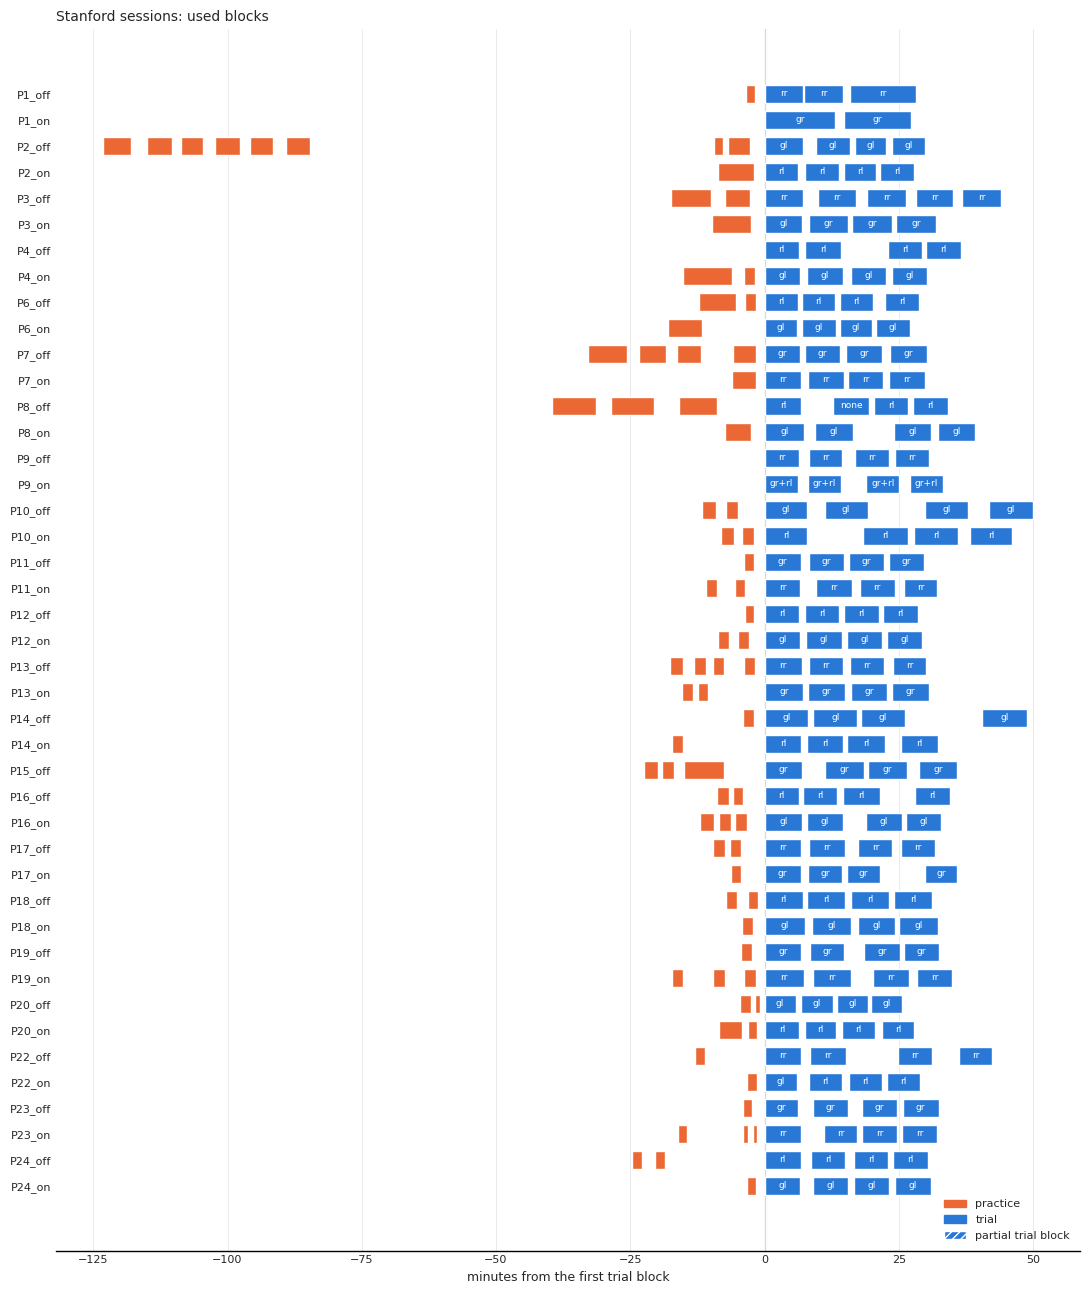

In [13]:
fig = blk.plot_timeline(blocks, summary[summary.n_trial_blocks > 0], "Stanford sessions: used blocks")
catalog.save_figure(fig, "stanford/session_timeline", root="artifacts")
plt.show()

## 9. Findings

Written out from the tables.

In [14]:
lines = blk.findings(blocks, summary, runs)
lines.append("Folder label differs from the data: "
             + ("; ".join(f"{r.folder} (data {r.session_prior})" for r in summary[~summary.folder_matches_data].itertuples()) or "none") + ".")
lines.append("Pre-combined file named differently from the data: "
             + ("; ".join(f"{r.combined_name} (data {r.session_prior})" for r in summary[~summary.combined_matches_data].itertuples()) or "none") + ".")
lines.append(f"Pre-combined files equal to their trial blocks: {combined.matches_blocks.sum()} of {len(combined)}; "
             f"sessions without one: {', '.join(summary.loc[summary.combined_name.isna(), 'session_id'])}.")
full_practice = practice[practice.kind == "full"].groupby("session_id", sort=False).n_shown.agg(["size", "sum"])
lines.append(f"Practice at all coherences (no prior), {len(full_practice)} sessions: "
             + "; ".join(f"{s} ({n} block(s), {t:.0f} trials)" for s, n, t in full_practice.itertuples()) + ".")
lines.append("Subtype prefix in a pre-combined file name differs from the folder: "
             + ("; ".join(f"{r.combined_name} in {r.folder}" for r in summary[summary.combined_subtype.notna() & (summary.combined_subtype != summary.folder_subtype)].itertuples()) or "none") + ".")
lines.append("Subtype prefix differs between a patient's sessions: " + (", ".join(f"{s} ({v})" for s, v in subtypes[subtypes.str.contains(",")].items()) or "none") + ".")
print("\n".join(f"- {line}" for line in lines))

- 250 files in 44 sessions; 246 used, 4 left out (3 session has no trial blocks, 1 aborted).
- 1 left-out file(s) (aborted) saved 2022-09-09 11:16, on the clock of P2_on, filed under P2_on.
- 3 left-out file(s) (session has no trial blocks) saved 2023-02-10 12:11-12:19, on the clock of no session that day, filed under P15_on.
- Sessions without trial blocks: P15_on.
- No practice recorded in-session: P1_on, P4_off, P9_off, P9_on.
- Practice not finished before the first trial block: none.
- Blocks out of order or trial blocks overlapping: none.
- Blocks on more than one day: none.
- Clock shifts within a session (sleep or clock correction; blocks kept): P1_off (up to 1.7 min); P2_off (up to 46.0 min); P8_on (up to 2.0 min).
- Block priors differ within the session: P3_on (gl | gr | gr | gr); P8_off (rl | none | rl | rl); P22_on (gl | rl | rl | rl).
- Design off 75:25 / 50:50 in a complete block: P8_off (rl); P9_on (gr+rl).
- Partial trial blocks: none.
- Under 600 trials: none; range 6

## 10. Compile

Each session with trial blocks: used practice then trial blocks, each in time order, with the shared session columns
plus the block each trial came from. P15 ON, which has no trial blocks, is not compiled.

Compiled data name a session by patient and medication state only (`P10_off`) and blocks by
`<session>/<path inside the session folder>`. The raw folder and pre-combined file names, with their subtype and
prior labels, stay in this notebook as findings about the raw data and are not saved: they are not reliable.

In [15]:
blk.compile_sessions(blocks, decoded, summary, "compiled_stanford_session")
RAW_LABELS = ["folder", "folder_subtype", "folder_prior", "combined_name", "combined_subtype", "combined_prior",
              "folder_matches_data", "combined_matches_data"]
catalog.save(blocks.drop(columns=blk.INTERNAL_COLUMNS), "compiled_stanford_blocks")
catalog.save(summary.drop(columns=RAW_LABELS).rename(columns={"matches_blocks": "combined_matches_blocks"}), "compiled_stanford_session_summary")

saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P1_off.parquet


saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P1_on.parquet


saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P2_off.parquet
saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P2_on.parquet


saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P3_off.parquet
saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P3_on.parquet


saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P4_off.parquet
saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P4_on.parquet


...

saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P19_on.parquet
saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P20_off.parquet
saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P20_on.parquet


saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P22_off.parquet
saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P22_on.parquet


saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P23_off.parquet
saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P23_on.parquet


saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P24_off.parquet
saved compiled_stanford_session -> /mnt/pd-data/compiled/stanford/sessions/P24_on.parquet


saved compiled_stanford_blocks -> /mnt/pd-data/compiled/stanford/blocks.csv
saved compiled_stanford_session_summary -> /mnt/pd-data/compiled/stanford/session_summary.csv


## 11. Selecting blocks later

As in 0.02: `catalog.load_block_sessions` and `src.utils.blocks.select_blocks`. P3 ON and P22 ON each ran one
correctly designed block with a different prior from the rest of the session; P8 OFF ran one block without a prior.

In [16]:
from src.utils.blocks import select_blocks

mixed = catalog.load_block_sessions(["stanford"], ["P3_on", "P22_on", "P8_off"])
display(mixed[mixed.phase == "trial"].groupby(["session_id", "block"]).agg(
    block_prior=("block_prior", "first"), trials=("block", "size"), design_ok=("block_design_ok", "first"),
    matches_session_prior=("block_matches_session_prior", "first")))
main = select_blocks(mixed, design_ok=True, matches_session_prior=True)  # the session's own prior, correctly run
other_prior = select_blocks(mixed, design_ok=True, matches_session_prior=False, relabel=True)  # e.g. P3 ON block 1 as gl
print({"main blocks": main.groupby("session_id").block.unique().to_dict(), "other-prior blocks": other_prior.groupby("session_id").prior.unique().to_dict()})

block_prior  trials  design_ok  matches_session_prior
session_id block                                                      
P22_on     1              gl     160       True                  False
           2              rl     160       True                   True
           3              rl     160       True                   True
           4              rl     160       True                   True
P3_on      1              gl     160       True                  False
           2              gr     160       True                   True
           3              gr     160       True                   True
           4              gr     160       True                   True
P8_off     1              rl     167       True                   True
           2            none     176      False                  False
           3              rl     168       True                   True
           4              rl     160       True                   True

{'main blocks': {'P22_on': array([2, 3, 4]), 'P3_on': array([2, 3, 4]), 'P8_off': array([1, 3, 4])}, 'other-prior blocks': {'P22_on': array(['gl'], dtype=object), 'P3_on': array(['gl'], dtype=object)}}
